# 03 — Analyse et insights métier

Objectif : répondre aux questions métier posées en introduction du README, avec des visualisations claires et des insights formulés en langage business.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('../data/raw/communes_occitanie_clean.csv')
df.head()

,Exercice,Code Insee 2025 Commune,Nom 2025 Commune,Nom 2025 Département,Strate population 2025,strate_label,Population totale,Epargne brute,Encours de dette,Recettes de fonctionnement,Dépenses d'investissement,Recettes totales,taux_endettement,ratio_investissement,epargne_brute_par_habitant
0,2018,9001,Aigues-Juntes,Ariège,0,Très petites communes,64,26044.43,0.00,48073.82,17174.78,49188.81,0.000000,0.349160,406.944219
1,2018,9002,Aigues-Vives,Ariège,3,Petites villes,663,83889.75,752163.15,340358.38,329318.49,775905.48,2.209915,0.424431,126.530543
2,2018,9003,L'Aiguillon,Ariège,2,Communes rurales,429,55448.87,158673.24,175253.30,120849.16,261322.61,0.905394,0.462452,129.251445
3,2018,9004,Albiès,Ariège,1,Petites communes,136,28044.88,20638.49,165632.94,49091.03,176471.96,0.124604,0.278180,206.212353
4,2018,9005,Aleu,Ariège,1,Petites communes,126,28469.39,215236.68,191581.99,40397.40,225819.04,1.123470,0.178893,225.947540


## Question 1 — Évolution de l'épargne brute par strate de population

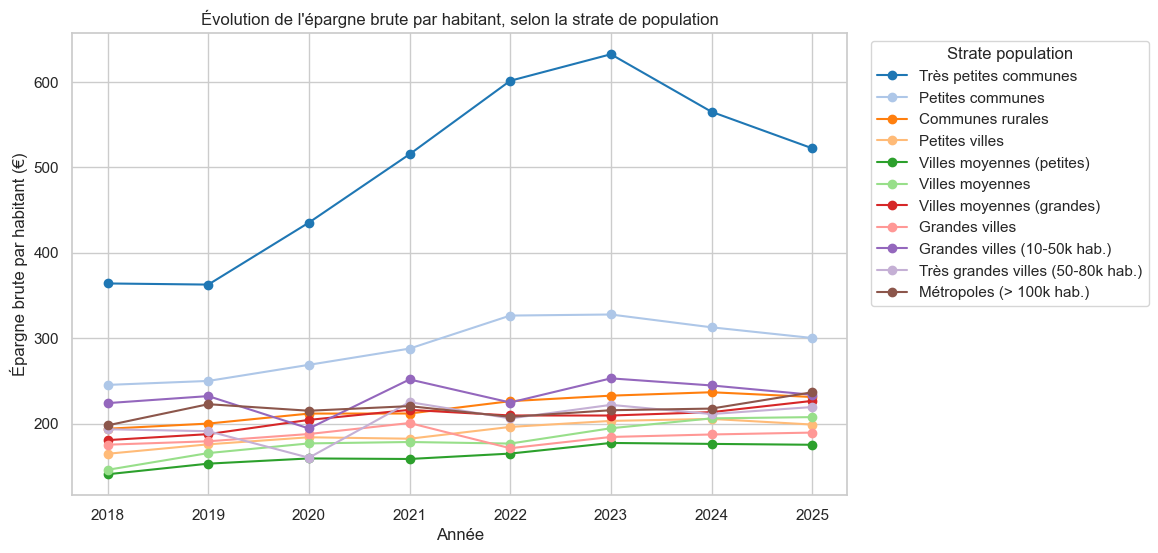

In [11]:
ordre_strates = [
    'Très petites communes', 'Petites communes', 'Communes rurales', 'Petites villes',
    'Villes moyennes (petites)', 'Villes moyennes', 'Villes moyennes (grandes)',
    'Grandes villes', 'Grandes villes (10-50k hab.)', 'Très grandes villes (50-80k hab.)',
    'Métropoles (> 100k hab.)'
]
evolution = df.groupby(['Exercice', 'strate_label'])['epargne_brute_par_habitant'].mean().unstack()
evolution = evolution[ordre_strates]

colors = plt.cm.tab20(range(len(ordre_strates)))
evolution.plot(marker='o', color=colors)
plt.title("Évolution de l'épargne brute par habitant, selon la strate de population")
plt.ylabel('Épargne brute par habitant (€)')
plt.xlabel('Année')
plt.legend(title='Strate population', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.savefig('../outputs/figures/epargne_brute_par_habitant_strate.png', dpi=150, bbox_inches='tight')
plt.show()

Insight :
L'épargne brute par habitant est nettement plus élevée dans les très petites communes (jusqu'à 3 fois supérieure aux strates intermédiaires en 2023), un écart qui s'explique en grande partie par un effet mécanique de dénominateur : certaines recettes fixes (dotations notamment) pèsent proportionnellement bien plus lourd rapportées à une population très faible. Cet écart ne traduit donc pas nécessairement une situation financière plus favorable, mais plutôt une structure budgétaire différente liée à la taille. À l'inverse, les strates intermédiaires (villes moyennes, grandes villes) présentent des niveaux d'épargne par habitant plus resserrés et stables dans le temps.

## Question 2 — Endettement vs recettes par strate

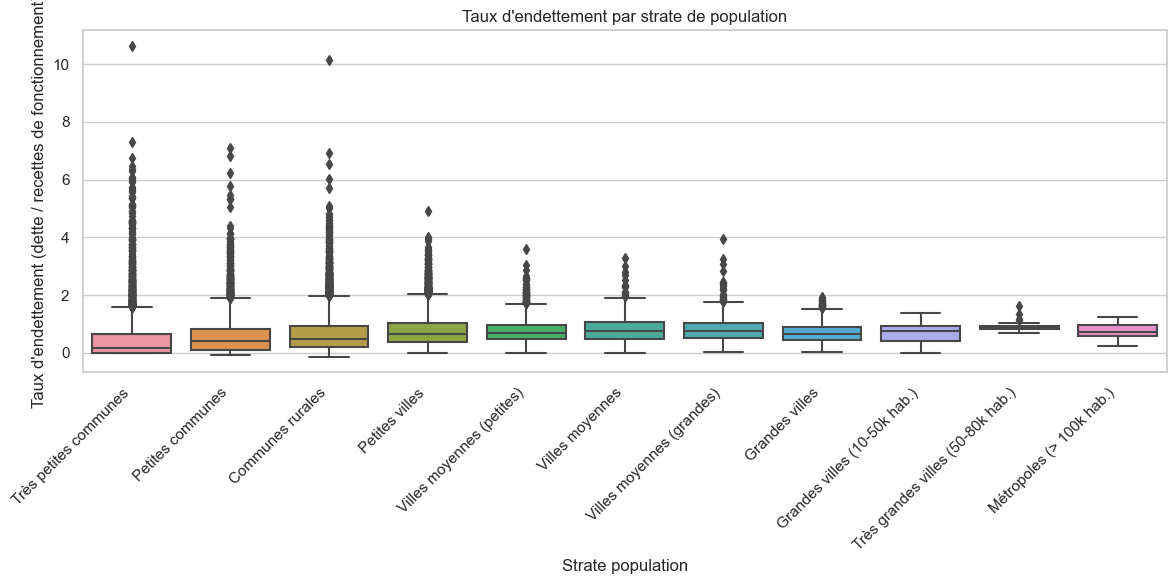

In [12]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='strate_label', y='taux_endettement', order=ordre_strates)
plt.xticks(rotation=45, ha='right')
plt.title("Taux d'endettement par strate de population")
plt.ylabel("Taux d'endettement (dette / recettes de fonctionnement)")
plt.xlabel('Strate population')
plt.tight_layout()
plt.savefig('../outputs/figures/endettement_par_strate.png', dpi=150, bbox_inches='tight')
plt.show()

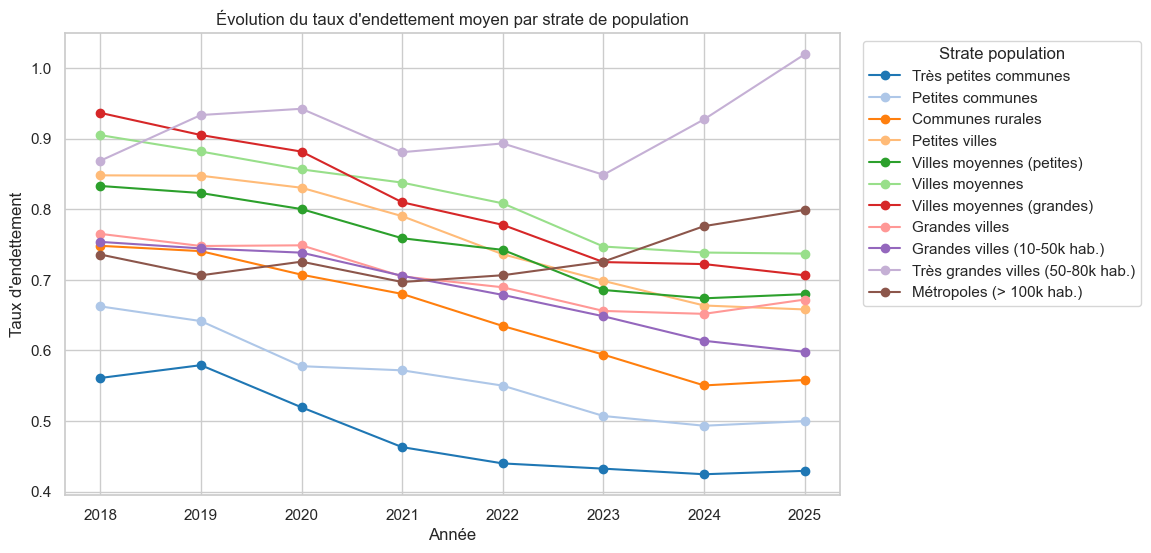

In [13]:
evolution_dette = df.groupby(['Exercice', 'strate_label'])['taux_endettement'].mean().unstack()
evolution_dette = evolution_dette[ordre_strates]

colors = plt.cm.tab20(range(len(ordre_strates)))
evolution_dette.plot(marker='o', color=colors)
plt.title("Évolution du taux d'endettement moyen par strate de population")
plt.ylabel("Taux d'endettement")
plt.xlabel('Année')
plt.legend(title='Strate population', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.savefig('../outputs/figures/evolution_endettement_strate.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
df[df['strate_label'] == 'Très grandes villes (50-80k hab.)'][['Exercice', 'Nom 2025 Commune', 'taux_endettement']].sort_values(['Nom 2025 Commune', 'Exercice'])

,Exercice,Nom 2025 Commune,taux_endettement
3974,2018,Albi,0.977811
8433,2019,Albi,0.895908
12887,2020,Albi,0.900668
17341,2021,Albi,0.849040
21795,2022,Albi,0.802617
26248,2023,Albi,0.802891
30701,2024,Albi,0.703509
35141,2025,Albi,0.754933
2485,2018,Béziers,0.915753
6959,2019,Béziers,0.870758


Insight :
La hausse apparente du taux d'endettement moyen de la strate "50-80k habitants" ne reflète pas une tendance partagée par l'ensemble des villes de cette taille : sur les 4 communes qui la composent (Albi, Béziers, Montauban, Narbonne), trois ont un endettement stable ou en baisse. C'est Montauban qui tire seule la moyenne vers le haut, avec un taux d'endettement passant de 0.87 en 2018 à 1.61 en 2025. Soit une dette supérieure à 1,6 fois ses recettes de fonctionnement annuelles, une accélération particulièrement marquée depuis 2023. Ce cas illustre les limites d'une lecture par moyenne de strate lorsque l'échantillon est restreint : un phénomène individuel peut être confondu avec une tendance de groupe.

## Question 3 — Poids de l'investissement dans le budget

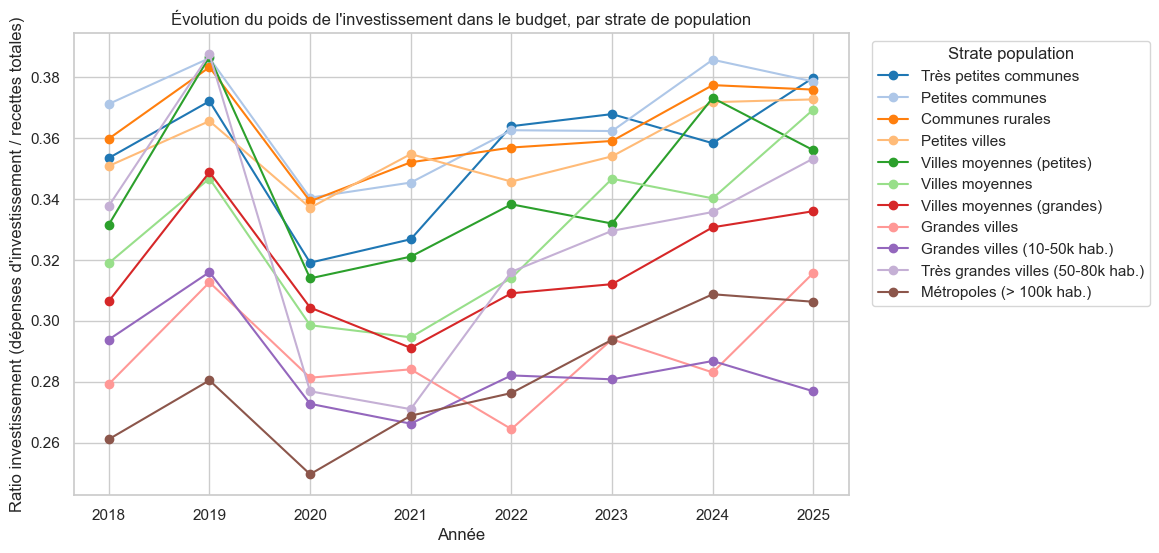

In [15]:
evolution_invest = df.groupby(['Exercice', 'strate_label'])['ratio_investissement'].mean().unstack()
evolution_invest = evolution_invest[ordre_strates]

colors = plt.cm.tab20(range(len(ordre_strates)))
evolution_invest.plot(marker='o', color=colors)
plt.title("Évolution du poids de l'investissement dans le budget, par strate de population")
plt.ylabel("Ratio investissement (dépenses d'investissement / recettes totales)")
plt.xlabel('Année')
plt.legend(title='Strate population', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.savefig('../outputs/figures/ratio_investissement_strate.png', dpi=150, bbox_inches='tight')
plt.show()

Insight :
Le ratio d'investissement suit un schéma cyclique cohérent avec le calendrier électoral municipal, observable sur l'ensemble des strates : un pic en 2019 (fin de mandat, avant les élections de mars 2020), suivi d'un net recul en 2020-2021 (début de mandat + ralentissement lié à la crise sanitaire), puis une remontée progressive jusqu'en 2024-2025 à l'approche des prochaines élections de 2026. Ce cycle, illustre que le niveau d'investissement d'une commune à un instant T ne peut pas être interprété isolément, il doit être lu en fonction de sa position dans le mandat municipal en cours.

On observe par ailleurs que les métropoles (>100k hab.) maintiennent un ratio d'investissement structurellement plus bas que toutes les autres strates sur l'ensemble de la période (jamais au-dessus de 0.31, contre plus de 0.38 pour les petites et moyennes communes en 2019 et 2024-2025). Cet écart peut s'expliquer par une part plus importante de dépenses de fonctionnement incompressibles dans les grandes villes (masse salariale, services publics étendus) qui limite mécaniquement la part disponible pour l'investissement, plutôt que par une moindre capacité d'investissement en valeur absolue.

## Synthèse
L'analyse des finances communales en Occitanie sur 2018-2025 révèle des dynamiques contrastées selon la taille des communes. L'épargne brute par habitant apparaît nettement supérieure dans les très petites communes, un effet largement mécanique lié à la faible population plutôt qu'à une situation financière réellement plus favorable. Contrairement à une idée reçue, l'endettement des communes occitanes tend globalement à diminuer sur la période. Les exceptions observées (comme Montauban) relèvent davantage de trajectoires individuelles que de tendances de strate, ce qui invite à la prudence dans la lecture de moyennes calculées sur de petits échantillons. Enfin, l'investissement communal suit un cycle clairement corrélé au calendrier électoral municipal, avec un niveau structurellement plus faible dans les grandes villes, probablement lié au poids plus important de leurs charges de fonctionnement fixes.
